# Pops’ Edge: one team-strength challenger

## tl;dr

**The challenger failed the agreed continuation gate.** Average annual paired
Brier gain was 0.000334 versus the required 0.001. It improved in 2025/2026 and
worsened slightly in 2024. The 14-day conditional 95% interval for average gain
is [−0.000257, +0.000790]. Retain the existing reference; no automatic new variant.

## Context & Methods

Tom authorized this one offline comparison on October 12, 2026. The protocol was
committed before challenger fitting. Replace six rolling team inputs with one
opponent-adjusted, 60-day-half-life ridge run rating; retain season progress and
three starter inputs. Fixed ridge penalty 20, previous-season multiplier 0.5;
L2 logistic C=1 and training-only scaling. Annual expanding fits evaluate
2024–2026. See `PROTOCOL.md`, `run.py` and `input_manifest.json`.

### Key Assumptions

All three seasons are reused development, not fresh holdouts. Historical actual
starters are assumed identities; final corrected data and prior-day availability
remain limitations. The intervals condition on fixed forecasts and omit model
selection/training uncertainty. There is no Kalshi or paper-return test here.

## Data

This notebook reads aggregate results only. Private per-game inputs, predictions
and rating lineage are excluded from Git. `verification.json` records exact
replay, arithmetic reconstruction and independent rating-solver checks.
Model fitting used NumPy 2.5.3, SciPy 1.18.1 and scikit-learn 1.9.1. Presentation
requires nbformat, nbclient, ipykernel and matplotlib; no credentials needed.


### 1. Load and verify the aggregate result

In [1]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
root = Path.cwd()
results = json.loads((root / 'results.json').read_text())
verification = json.loads((root / 'verification.json').read_text())
assert verification['unique_paired_games'] == 7280
assert verification['gate_failed'] and not results['continuation_gate_passed']
assert verification['annual_scores_independently_recomputed']
plt.rcParams.update({'font.size': 11, 'figure.dpi': 140,
                     'axes.spines.top': False, 'axes.spines.right': False})
years = ['2024', '2025', '2026']
print('7,280 paired games; reference replay exact in all years; continuation gate failed.')

7,280 paired games; reference replay exact in all years; continuation gate failed.


## Results

### 2. Annual paired scores

Lower Brier and log loss are better. Positive gain below means the challenger improved.

In [2]:
table = '| Season | Games | Reference Brier | Challenger Brier | Gain | Reference log loss | Challenger log loss |\n|---|---:|---:|---:|---:|---:|---:|\n'
for year in years:
    a = results['annual'][year]
    table += f"| {year} | {a['reference']['games']:,} | {a['reference']['brier']:.6f} | {a['challenger']['brier']:.6f} | {results['annual_brier_gains'][year]:+.6f} | {a['reference']['log_loss']:.6f} | {a['challenger']['log_loss']:.6f} |\n"
display(Markdown(table))

| Season | Games | Reference Brier | Challenger Brier | Gain | Reference log loss | Challenger log loss |
|---|---:|---:|---:|---:|---:|---:|
| 2024 | 2,426 | 0.243134 | 0.243249 | -0.000115 | 0.679228 | 0.679490 |
| 2025 | 2,426 | 0.243886 | 0.243647 | +0.000239 | 0.680590 | 0.680060 |
| 2026 | 2,428 | 0.246136 | 0.245258 | +0.000879 | 0.685346 | 0.683490 |


### 3. Gains and uncertainty

Paired 14-day moving-calendar-block percentile 95% intervals, 5,000 replicates. The primary measure averages annual gains equally; its practical threshold is 0.001.

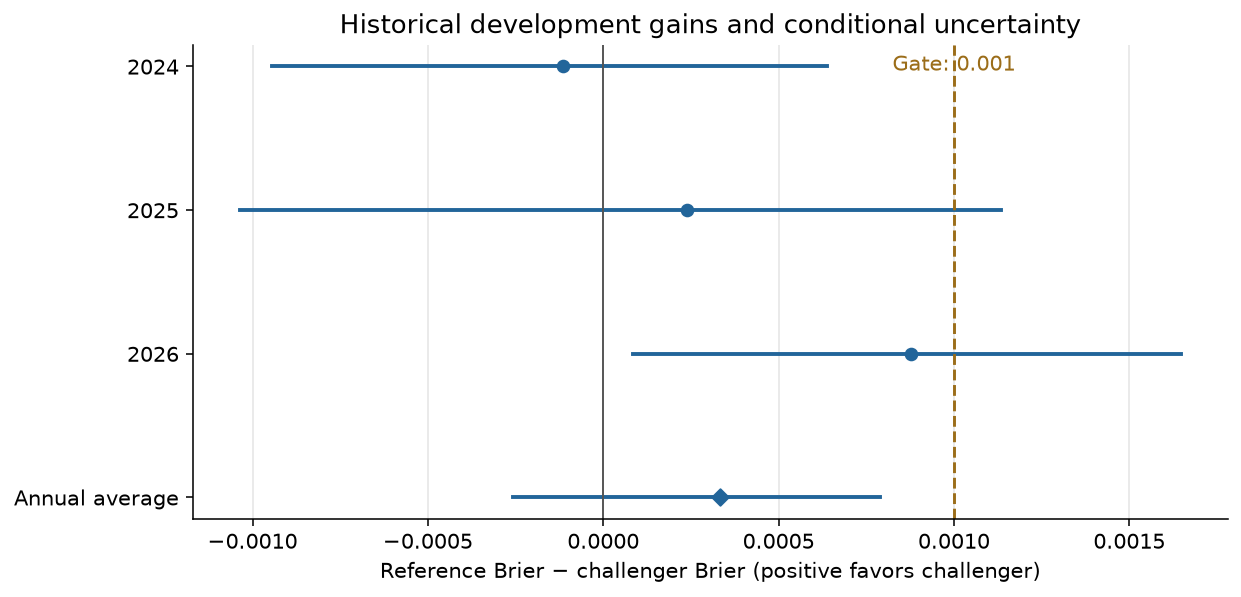

In [3]:
labels = years + ['Annual average']
gains = [results['annual_brier_gains'][y] for y in years] + [results['equal_weight_annual_brier_gain']]
bounds = [results['bootstrap']['14']['annual'][y]['brier'] for y in years] + [results['bootstrap']['14']['equal_weight_annual_brier']]
fig, ax = plt.subplots(figsize=(9, 4.4))
for i, (gain, bound) in enumerate(zip(gains, bounds)):
    ax.plot([bound['lower'], bound['upper']], [i, i], color='#22659A', linewidth=2)
    ax.scatter([gain], [i], color='#22659A', marker='o' if i < 3 else 'D', zorder=3)
ax.axvline(0, color='#555555', linewidth=1)
ax.axvline(.001, color='#9B6D19', linestyle='--', label='Agreed continuation threshold')
ax.set_yticks(range(4), labels)
ax.invert_yaxis()
ax.set_xlabel('Reference Brier − challenger Brier (positive favors challenger)')
ax.set_title('Historical development gains and conditional uncertainty')
ax.grid(axis='x', color='#E5E5E5')
ax.text(.001, .98, 'Gate: 0.001', transform=ax.get_xaxis_transform(), ha='center', va='top', color='#9B6D19')
fig.tight_layout()
fig.savefig(root / 'brier_gains.png', dpi=180)
plt.show()

The average gain falls short of 0.001 and its interval includes zero. The stronger 2026 gain does not override the predeclared three-season decision rule. Seven-day sensitivity also leaves the average interval spanning zero.

### 4. Calibration diagnostic

An ideal calibration slope is 1. These are descriptive fits on each evaluated season, never corrections applied to forecasts.

In [4]:
table = '| Season | Reference intercept | Challenger intercept | Reference slope | Challenger slope |\n|---|---:|---:|---:|---:|\n'
for year in years:
    c = results['calibration'][year]
    table += f"| {year} | {c['reference']['intercept']:.3f} | {c['challenger']['intercept']:.3f} | {c['reference']['slope']:.3f} | {c['challenger']['slope']:.3f} |\n"
display(Markdown(table))
print('Coverage unchanged; 914 rating dates; no empty-history fallback dates.')

| Season | Reference intercept | Challenger intercept | Reference slope | Challenger slope |
|---|---:|---:|---:|---:|
| 2024 | -0.020 | -0.022 | 0.987 | 1.011 |
| 2025 | 0.087 | 0.085 | 0.843 | 0.860 |
| 2026 | 0.021 | 0.008 | 0.782 | 0.888 |


Coverage unchanged; 914 rating dates; no empty-history fallback dates.


## Takeaways

The one challenger is complete and not promoted. Pooled log loss improved and
coverage stayed identical, but the required average Brier gain was not met.
Retain the reference as a research baseline. Any next model experiment or
paper-alert implementation needs a separate discussion; no new sweep or
threshold relaxation follows automatically.

The existing review’s sportsbook opening consensus is a different comparator
from same-time Kalshi forecasts and executable prices. No demonstrated
undervaluation, edge or positive net return follows from this experiment.

### Verification scope

All seven saved replay artifacts match exactly. All 914 date-level source sets
were checked for chronology; 15 outcome-blind first/middle/last dates were checked
using an independent augmented least-squares rating solve. Saved probabilities
and annual proper scores reconstruct within floating-point precision. Five
synthetic chronology/equation tests passed. Raw player-feature acquisition was
not rebuilt. See `verification.json` for machine-readable evidence.
